# Libraries Import

In [21]:
import sqlite3
import pandas as pd
from rdkit import Chem
from rdkit.Chem import Draw

In [22]:
#estrazione dati da ChEMBL e creazione dataset ridotto 15000 righe

"""
    connessione = sqlite3.connect('data/chembl_36.db') 

    query = \"""
        SELECT 
            md.chembl_id AS molecule_id,       
            td.chembl_id AS target_id,         
            cs.canonical_smiles AS smiles, 
            act.standard_type AS measure_type,  
            act.standard_units AS measure_unit,
            act.standard_value AS affinity, 
            ts.sequence AS protein_sequence
        FROM activities act
        JOIN assays a ON act.assay_id = a.assay_id
        JOIN target_dictionary td ON a.tid = td.tid
        JOIN target_components tc ON td.tid = tc.tid
        JOIN component_sequences ts ON tc.component_id = ts.component_id
        JOIN compound_structures cs ON act.molregno = cs.molregno
        JOIN molecule_dictionary md ON act.molregno = md.molregno 
        WHERE act.standard_type IN ('IC50', 'Ki', 'Kd') 
        AND act.standard_value IS NOT NULL
        AND cs.canonical_smiles IS NOT NULL
        LIMIT 15000;
    \"""

    df_mini = pd.read_sql_query(query, connessione)
    connessione.close()

    df_mini.to_csv('mini_dataset_chembl.csv', index=False)
    print("Fatto! Ho creato 'mini_dataset_chembl.csv'.")
    df_mini.head() # Così vedi subito se ha funzionato!

"""

'\n    connessione = sqlite3.connect(\'data/chembl_36.db\') \n\n    query = """\n        SELECT \n            md.chembl_id AS molecule_id,       \n            td.chembl_id AS target_id,         \n            cs.canonical_smiles AS smiles, \n            act.standard_type AS measure_type,  \n            act.standard_units AS measure_unit,\n            act.standard_value AS affinity, \n            ts.sequence AS protein_sequence\n        FROM activities act\n        JOIN assays a ON act.assay_id = a.assay_id\n        JOIN target_dictionary td ON a.tid = td.tid\n        JOIN target_components tc ON td.tid = tc.tid\n        JOIN component_sequences ts ON tc.component_id = ts.component_id\n        JOIN compound_structures cs ON act.molregno = cs.molregno\n        JOIN molecule_dictionary md ON act.molregno = md.molregno \n        WHERE act.standard_type IN (\'IC50\', \'Ki\', \'Kd\') \n        AND act.standard_value IS NOT NULL\n        AND cs.canonical_smiles IS NOT NULL\n        LIMIT 15000

# DATA OVERVIEW

In [23]:
df = pd.read_csv('data/mini_dataset_chembl.csv')
df.head()

# Investigating the dataset
print(f"\nDataset shape: {df.shape}")
print(f"Dataset columns: {df.columns.tolist()}")
print(f"Dataset sample: {df.iloc[0]}")



Dataset shape: (15000, 7)
Dataset columns: ['molecule_id', 'target_id', 'smiles', 'measure_type', 'measure_unit', 'affinity', 'protein_sequence']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   molecule_id       15000 non-null  object 
 1   target_id         15000 non-null  object 
 2   smiles            15000 non-null  object 
 3   measure_type      15000 non-null  object 
 4   measure_unit      15000 non-null  object 
 5   affinity          15000 non-null  float64
 6   protein_sequence  15000 non-null  object 
dtypes: float64(1), object(6)
memory usage: 820.4+ KB

Dataset info: None
Dataset sample: molecule_id                                              CHEMBL113081
target_id                                                  CHEMBL1806
smiles                       c1ccc(-c2nc3c(-c4nc5ccccc5o4)cccc3o2)cc1
measure_type          

c:\Users\isare\AppData\Local\Programs\Python\Python311\Lib\site-packages\rdkit\Chem\Draw\IPythonConsole.py:365: UserWarning: Truncating the list of molecules to be displayed to 50. Change the maxMols value to display more.
  warnings.warn(


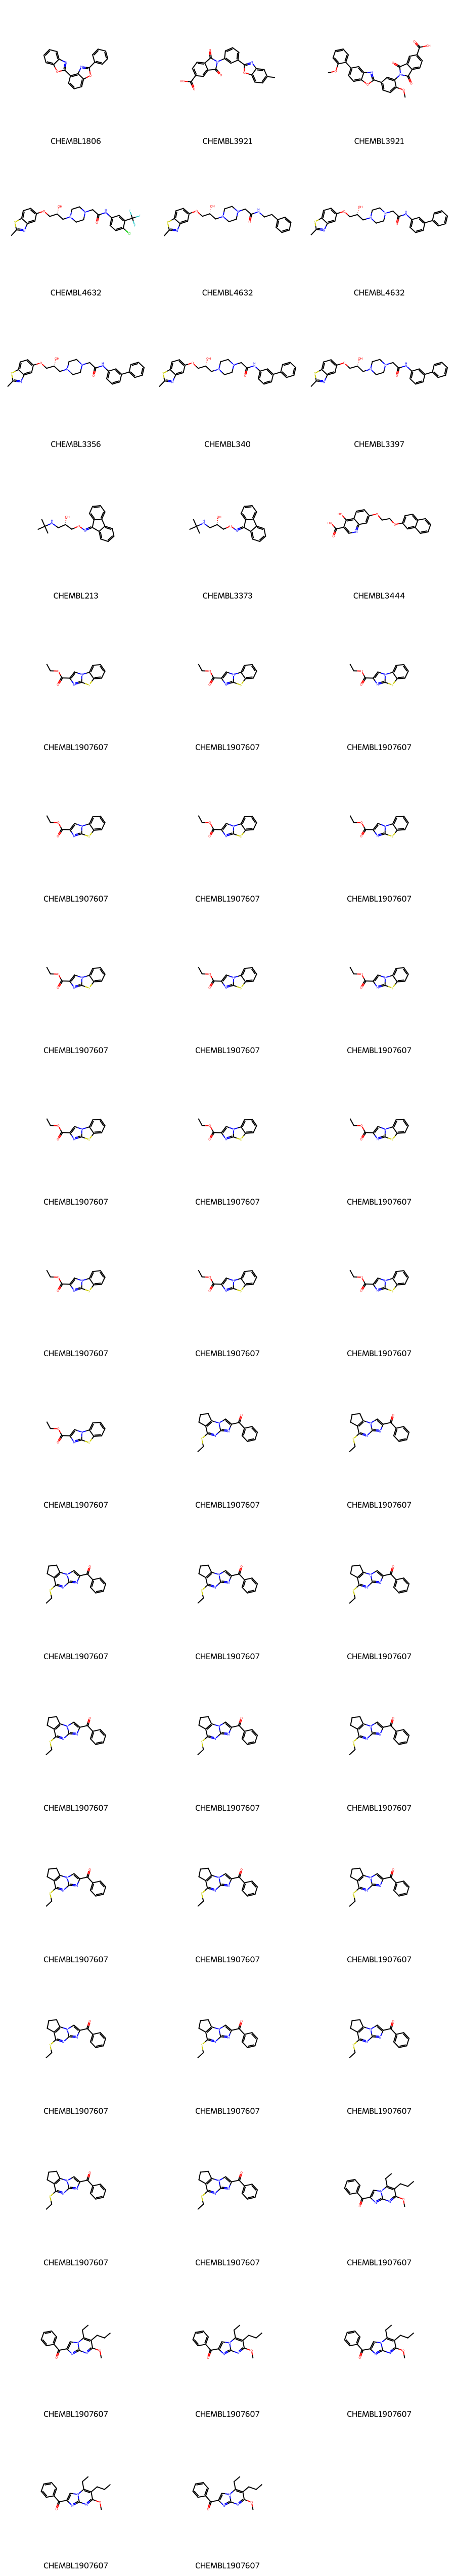

In [ ]:
  
#plottare le molecole con RDKit

lista_molecole = []
nomi_molecole = []


for index, row in df.iterrows():
    smiles = row['smiles']
    nome = row['target_id']  
    
    molecola = Chem.MolFromSmiles(smiles)
    

    if molecola is not None:
        lista_molecole.append(molecola)
        nomi_molecole.append(nome)

if len(lista_molecole) > 0:
    immagine = Draw.MolsToGridImage(
        lista_molecole, 
        molsPerRow=3,           
        subImgSize=(300, 300),  
        legends=nomi_molecole   
    )
    
display(immagine)  
   